In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, IFrame, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
RES = ROOT / "results"
def show_png(path, width=620):
    display(Image(filename=str(path), width=width))

# 04 · Bayesian hyperparameter optimisation
Method: **Optuna TPE** (seed 42). Objective: mean observation-level Top-1 under 3-fold GroupKFold by trip, on a seeded
sample of the train trips (`SEARCH_TRIPS`) to keep each trial cheap. The best configuration is then refit on all 80 train trips and compared
with the untuned model on the **same** trip-grouped folds of all 80 trips (identical to notebook 03) and on student_test. The final model is chosen by cross-validation, not by student_test.
Code: `optimisation/bayes_tune.py`.

In [2]:
bp = json.loads((ROOT / "artifacts/best_params.json").read_text())
print(json.dumps(bp, indent=2))

{
  "model": "hist_gradient_boosting",
  "tuned": true,
  "selected_file": "hist_gradient_boosting_tuned",
  "alt_model": "random_forest",
  "best_params": {
    "learning_rate": 0.09304854626697996,
    "max_iter": 189,
    "max_leaf_nodes": 50,
    "min_samples_leaf": 181,
    "l2_regularization": 0.0001601173409473354
  },
  "untuned_params": {
    "l2_regularization": 0.0,
    "learning_rate": 0.1,
    "max_iter": 150,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 20
  },
  "search": {
    "sampler": "TPE",
    "n_trials": 20,
    "folds": 3,
    "trips": 36,
    "objective": "mean observation-level Top-1",
    "best_objective": 0.8494302960594217,
    "seconds": 555.1264621999871,
    "seed": 42
  }
}


20 trials


,number,value,params_l2_regularization,params_learning_rate,params_max_iter,params_max_leaf_nodes,params_min_samples_leaf
17,17,0.8494,0.0002,0.0930,189,50,181
15,15,0.8488,0.0155,0.1103,199,55,159
13,13,0.8487,0.0002,0.0997,209,57,186
11,11,0.8487,0.0037,0.0887,214,61,152
0,0,0.8486,0.0006,0.0551,241,50,128
18,18,0.8483,0.0001,0.1167,213,45,153
7,7,0.8482,0.0159,0.1786,118,19,143
2,2,0.8480,0.0008,0.0211,245,55,58
9,9,0.8479,0.0008,0.1203,119,40,118
5,5,0.8479,0.0002,0.1677,98,40,127


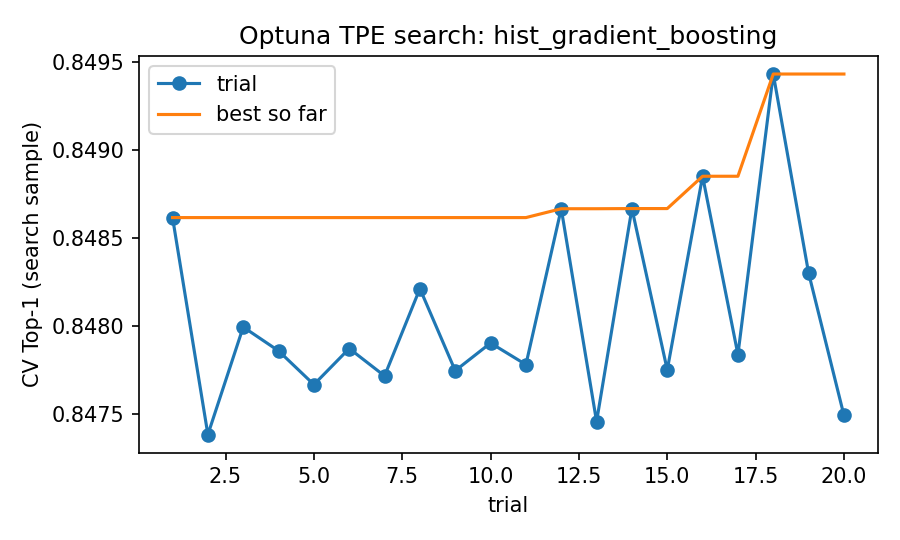

In [3]:
tr = pd.read_csv(RES / "optuna_trials.csv")
print(len(tr), "trials")
param_cols = [c for c in tr.columns if c.startswith("params_")]
display(tr[["number","value"] + param_cols].sort_values("value", ascending=False).head(10).round(4))
show_png(RES / "figures/optuna_history.png", 520)

## Tuned vs untuned (same metrics, same partitions)

In [4]:
tc = pd.read_csv(RES / "tuning_comparison.csv")
display(tc.round(4))
u, t = tc.iloc[0], tc.iloc[1]
print(f"CV Top-1 {u.cv_top1:.4f} -> {t.cv_top1:.4f}; student_test Top-1 {u.test_top1:.4f} -> {t.test_top1:.4f}; log loss {u.test_log_loss:.4f} -> {t.test_log_loss:.4f}")
print("Selected for deployment:", bp["selected_file"], "| alternative kept for comparison:", bp["alt_model"])

,model,configuration,cv_top1,cv_macro_f1,cv_log_loss,test_top1,test_macro_f1,test_log_loss,test_route_continuity,fit_seconds,infer_ms_per_1k_rows
0,hist_gradient_boosting,untuned,0.7432,0.8889,0.1650,0.8563,0.9162,0.1092,0.9358,6.8391,2.1391
1,hist_gradient_boosting,tuned (Optuna TPE),0.7443,0.8888,0.1677,0.8586,0.9173,0.1075,0.9370,17.0198,4.8657


CV Top-1 0.7432 -> 0.7443; student_test Top-1 0.8563 -> 0.8586; log loss 0.1092 -> 0.1075
Selected for deployment: hist_gradient_boosting_tuned | alternative kept for comparison: random_forest


The gain from tuning is small compared with the fold-to-fold variation (see `cv_top1_std` in notebook 03): the default configuration was already close to the optimum, and most of the final accuracy comes from the features and the HMM decoder.